# 03 — Baselines và so sánh mô hình trên Validation

Huấn luyện bốn thuật toán from-scratch và hai baselines. Chỉ dùng **Validation** để so sánh. Test chưa được dự đoán trong notebook này. Tất cả bảng đánh giá tiền tệ dùng BRL sau inverse log.

Lần chạy này dùng `FAST_MODE=False`: bốn mô hình, baselines và mọi cấu hình tuning học trên toàn bộ Train; Validation/Test giữ nguyên. Có thể bật fast mode để smoke test, nhưng các outputs được lưu ở đây là kết quả full Train.

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import CustomDataPipeline, weekly_split_data
from src.models import regressors, persistence
from src.deployment import predictor
from src.evaluation import metrics, error_analysis

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(config.NOTEBOOK_FIGURES_DIR / filename, dpi=config.FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def revenue(log_values):
    return np.maximum(0.0, np.expm1(np.asarray(log_values, dtype=float)))

print("Trình thông dịch Trình thông dịch Python:", sys.executable)
print("Thư mục dự án:", PROJECT_ROOT)

Trình thông dịch Trình thông dịch Python: e:\Hoc_May_Tren_truong\lab_2 sales_predictor\.venv\Scripts\python.exe
Thư mục dự án: e:\Hoc_May_Tren_truong\lab_2 sales_predictor


In [2]:
required = [config.CACHE_PIPELINE, config.CACHE_X_TRAIN, config.CACHE_Y_TRAIN,
            config.CACHE_X_VAL, config.CACHE_Y_VAL, config.CACHE_X_TEST, config.CACHE_Y_TEST]
if not all(p.exists() for p in required):
    raise FileNotFoundError("Chạy notebook 02 trước để tạo weekly cache.")
pipeline = CustomDataPipeline.load(config.CACHE_PIPELINE)
assert getattr(pipeline, "forecast_granularity_", None) == "product_week", "Cache không phải weekly. Chạy lại notebook 02."
X_train, X_val, X_test = [sp.load_npz(p) for p in [config.CACHE_X_TRAIN, config.CACHE_X_VAL, config.CACHE_X_TEST]]
y_train, y_val, y_test = [np.load(p) for p in [config.CACHE_Y_TRAIN, config.CACHE_Y_VAL, config.CACHE_Y_TEST]]
cache_fingerprint = json.loads((config.PROCESSED_DATA_DIR / "cache_manifest.json").read_text(encoding="utf-8"))["fingerprint"]
feature_names = pipeline.feature_names_
display(pd.DataFrame({"Split": ["Train", "Validation", "Test"],
                      "Shape": [str(x.shape) for x in [X_train, X_val, X_test]]}))

,Split,Shape
0,Train,"(655066, 89)"
1,Validation,"(249399, 89)"
2,Test,"(293717, 89)"


## 1. Baseline và mô hình

| Candidate | Vai trò / trade-off |
|---|---|
| Mean Baseline | Hằng số bằng trung bình nhãn log Train; inverse log không phải trung bình doanh thu BRL |
| Previous Week Baseline | Dự báo doanh thu tuần trước; dễ giải thích nhưng yếu với nhu cầu thưa/đột biến |
| Linear Regression | Mốc tuyến tính; ngoại suy rồi `expm1` có thể tạo sai số rất lớn |
| Decision Tree | Học ngưỡng phi tuyến; có thể overfit các nhóm nhỏ |
| Random Forest | Bagging giảm biến động giữa cây; tăng chi phí fit/predict |
| Gradient Boosting | Học phần dư tuần tự; nhạy learning rate và đuôi doanh thu |
| Two-Stage Hurdle | Tách 2 giai đoạn: xác suất bán P(y>0) và độ lớn E[y|y>0]; đặc trị >90% tuần bằng 0 BRL |

Tối ưu trong log space và lựa chọn theo RMSE BRL là hai mục tiêu khác nhau. Không giả định mô hình phức tạp sẽ thắng baseline.

In [3]:
from main import step_6_train_models
FAST_MODE = False
trained = step_6_train_models(X_train, y_train, fast_mode=FAST_MODE, pipeline=pipeline)
val_revenue = revenue(y_val)
records = []
for name, item in trained.items():
    prediction = revenue(item["model"].predict(X_val))
    records.append({"Model": name, **metrics.compute_extended_metrics(val_revenue, prediction), "Fit seconds": item["fit_time"]})
validation_table = pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(validation_table)
validation_table.to_csv(config.NOTEBOOK_METRICS_DIR / "weekly_validation_comparison.csv", index=False)
bundle = {"trained": trained, "pipeline": pipeline, "fingerprint": cache_fingerprint, "fast_mode": FAST_MODE}
with (config.NOTEBOOK_SAVED_MODELS_DIR / "weekly_candidates.pkl").open("wb") as handle:
    pickle.dump(bundle, handle)


★★★★★★★★★★★★★ BƯỚC 6: HUẤN LUYỆN 4 THUẬT TOÁN HỒI QUY FROM SCRATCH ★★★★★★★★★★★★★

[2026-10-18 16:55:42] [INFO] [sales_predictor]: ► Đang huấn luyện: [Linear Regression]...
[2026-10-18 16:55:43] [INFO] [sales_predictor]:   ✓ [Linear Regression] hoàn tất trong 0.54s
[2026-10-18 16:55:43] [INFO] [sales_predictor]: ► Đang huấn luyện: [Decision Tree]...
[2026-10-18 16:56:00] [INFO] [sales_predictor]:   ✓ [Decision Tree] hoàn tất trong 17.79s
[2026-10-18 16:56:00] [INFO] [sales_predictor]: ► Đang huấn luyện: [Random Forest]...
[2026-10-18 16:57:10] [INFO] [sales_predictor]:   ✓ [Random Forest] hoàn tất trong 69.08s
[2026-10-18 16:57:10] [INFO] [sales_predictor]: ► Đang huấn luyện: [Gradient Boosting]...
[2026-10-18 17:00:28] [INFO] [sales_predictor]:   ✓ [Gradient Boosting] hoàn tất trong 198.49s


,Model,MSE,MAE,RMSE,R2,Fit seconds
0,Decision Tree,3.741326e+03,5.674860e+00,6.116638e+01,6.789397e-02,17.790182
1,Gradient Boosting,3.944522e+03,5.774078e+00,6.280543e+01,1.727000e-02,198.485064
2,Random Forest,3.982953e+03,5.797061e+00,6.311064e+01,7.695353e-03,69.080891
3,Revenue Mean Baseline,4.019509e+03,1.319754e+01,6.339960e+01,-1.412115e-03,0.000000
4,Mean Baseline,4.043203e+03,5.875679e+00,6.358619e+01,-7.315218e-03,0.000000
5,Zero Baseline,4.045813e+03,5.654400e+00,6.360671e+01,-7.965497e-03,0.000000
6,Previous Week Baseline,6.708470e+03,1.088610e+01,8.190525e+01,-6.713343e-01,0.000000
7,Linear Regression,4.071589e+20,5.539149e+07,2.017818e+10,-1.014387e+17,0.537354


## 2. Đọc kết quả đúng thang đo

MSE tính bằng BRL²; MAE và RMSE bằng BRL; R² có thể âm. Đồ thị RMSE dùng trục log để các mô hình không bị che bởi một candidate ngoại suy rất lớn; metric vẫn là RMSE BRL, không phải RMSE log.

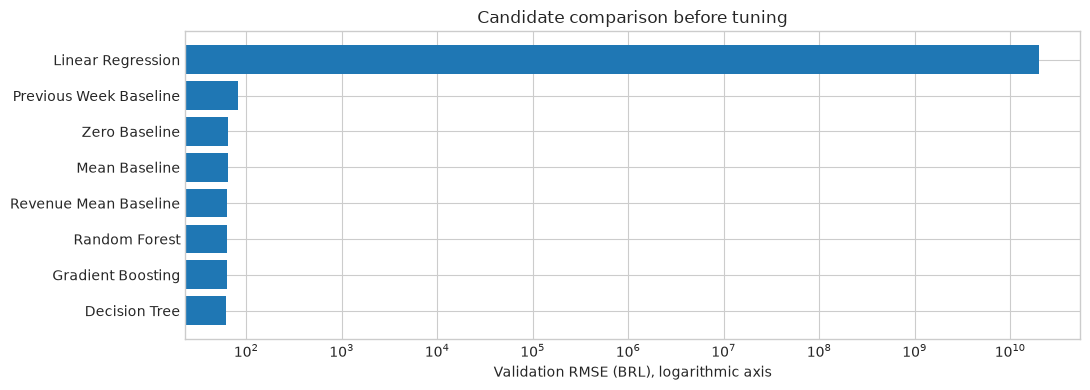

### Nhận xét từ Validation
- Candidate có RMSE thấp nhất trước tuning: **Decision Tree**, **61.1664 BRL**, R² **0.0679**.
- Persistence baseline đạt **81.9053 BRL**. Chênh lệch này chỉ mô tả Validation, chưa phải bằng chứng hiệu quả vận hành.
- Không diễn giải R² thành phần trăm dự đoán đúng. Chưa chọn bằng Test; notebook 04 sẽ bổ sung candidate đã tuning rồi khóa lựa chọn.


In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(validation_table.Model, validation_table.RMSE)
ax.set_xscale("log")
ax.set(xlabel="Validation RMSE (BRL), logarithmic axis", title="Candidate comparison before tuning")
show_figure(fig, "weekly_03_validation_rmse.png")
leader = validation_table.iloc[0]
baseline_rmse = float(validation_table.set_index("Model").loc["Previous Week Baseline", "RMSE"])
display(Markdown(f"""### Nhận xét từ Validation
- Candidate có RMSE thấp nhất trước tuning: **{leader['Model']}**, **{leader['RMSE']:.4f} BRL**, R² **{leader['R2']:.4f}**.
- Persistence baseline đạt **{baseline_rmse:.4f} BRL**. Chênh lệch này chỉ mô tả Validation, chưa phải bằng chứng hiệu quả vận hành.
- Không diễn giải R² thành phần trăm dự đoán đúng. Chưa chọn bằng Test; notebook 04 sẽ bổ sung candidate đã tuning rồi khóa lựa chọn.
"""))

## 3. Công thức, tham số và lý do lựa chọn

Gọi $z=\log(1+y)$, các mô hình học $\hat z=f(X)$; doanh thu suy luận là $\max(0,\exp(\hat z)-1)$.

- **Linear Regression:** nghiệm ridge nhỏ $w=(X^TX+\alpha I)^{+}X^Tz$, không regularize intercept. Giá trị $\alpha$ thực tế được in từ model; inverse log có thể khuếch đại ngoại suy.
- **Decision Tree:** chọn split giảm tổng bình phương sai số của $z$; giới hạn depth/min leaf kiểm soát độ phức tạp. Quantile candidates giảm số ngưỡng cần thử.
- **Random Forest:** bootstrap theo dòng Train, chọn tập con feature ở mỗi nút; trung bình dự đoán cây. Bootstrap hiện tại không phải block bootstrap thời gian.
- **Gradient Boosting:** khởi tạo mean $z$, lặp fit cây vào residual $z-F(X)$, cập nhật $F\leftarrow F+\eta h(X)$.
- **Mean Baseline:** $\hat z=\overline z_{train}$; **Previous Week Baseline:** $\hat y=y_{t-1}$. Mean log không phải nghiệm tối ưu hằng số cho MSE BRL.

Tất cả được kiểm tra ngoài mẫu bằng Validation RMSE BRL; tăng độ phức tạp chỉ hợp lý khi vượt baseline và không tạo gap Train–Validation quá lớn.

In [5]:
parameter_names = ["solver", "alpha_ridge", "max_depth", "classifier_max_depth", "regressor_max_depth", "min_samples_split", "min_samples_leaf", "n_estimators", "learning_rate", "max_features", "n_quantiles", "random_state"]
parameter_rows = []
for name, item in trained.items():
    model = item["model"]
    parameter_rows.append({"Model": name, **{key: getattr(model, key) for key in parameter_names if hasattr(model, key)}})
display(pd.DataFrame(parameter_rows).fillna("—"))


,Model,solver,alpha_ridge,learning_rate,random_state,max_depth,min_samples_split,min_samples_leaf,max_features,n_quantiles,n_estimators
0,Zero Baseline,—,—,—,—,—,—,—,—,—,—
1,Revenue Mean Baseline,—,—,—,—,—,—,—,—,—,—
2,Mean Baseline,—,—,—,—,—,—,—,—,—,—
3,Previous Week Baseline,—,—,—,—,—,—,—,—,—,—
4,Linear Regression,normal_equation,0.00001,0.01,42.0,—,—,—,—,—,—
5,Decision Tree,—,—,—,42.0,5.0,20.0,10.0,—,16.0,—
6,Random Forest,—,—,—,42.0,6.0,20.0,10.0,sqrt,16.0,15.0
7,Gradient Boosting,—,—,0.1,42.0,3.0,10.0,5.0,—,16.0,15.0


## 4. Đối chiếu Train–Validation: lỗi và dấu hiệu overfit

Đánh giá trên chính mẫu Train đã dùng để fit khi fast mode; baselines dùng toàn bộ Train để fit như định nghĩa. Tách rõ RMSE log (khớp mục tiêu huấn luyện) và RMSE BRL (tiêu chí kinh doanh). Gap khác 0 có thể do overfit **hoặc** thay đổi phân bố thời gian; không kết luận chỉ từ một con số.

,Model,Fit-sample RMSE BRL,Validation RMSE BRL,Fit-sample R2,Validation R2,Fit-sample RMSE log,Validation RMSE log,Val minus Train RMSE BRL
0,Zero Baseline,7.379505e+01,6.360671e+01,-1.199814e-02,-7.965497e-03,1.010120,0.828251,-1.018834e+01
1,Revenue Mean Baseline,7.335629e+01,6.339960e+01,0.000000e+00,-1.412115e-03,2.221159,2.215437,-9.956692e+00
2,Mean Baseline,7.376976e+01,6.358619e+01,-1.130452e-02,-7.315218e-03,0.987698,0.819092,-1.018357e+01
3,Previous Week Baseline,9.863398e+01,8.190525e+01,-8.079164e-01,-6.713343e-01,1.404240,1.133162,-1.672872e+01
4,Linear Regression,8.079175e+07,2.017818e+10,-1.212996e+12,-1.014387e+17,0.922792,0.774302,2.009739e+10
5,Decision Tree,7.106350e+01,6.116638e+01,6.153413e-02,6.789397e-02,0.903694,0.748255,-9.897127e+00
6,Random Forest,7.319949e+01,6.311064e+01,4.270578e-03,7.695353e-03,0.910270,0.751295,-1.008884e+01
7,Gradient Boosting,7.294854e+01,6.280543e+01,1.108608e-02,1.727000e-02,0.908317,0.749160,-1.014311e+01


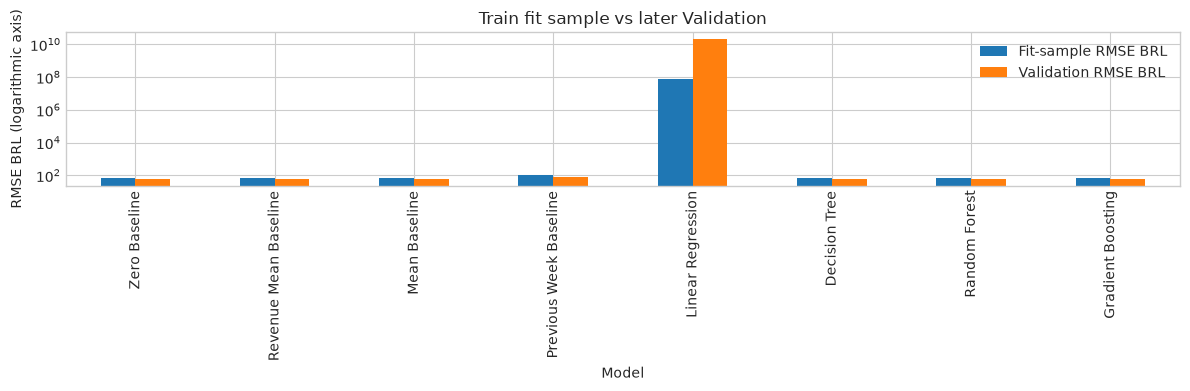

Nếu Linear Regression có RMSE BRL rất lớn nhưng log error ít nổi bật hơn, nguyên nhân có thể là khuếch đại sau expm1. Không xóa kết quả kém hoặc thay đổi Test để làm đẹp bảng. Chưa có repeated temporal folds để định lượng độ ổn định.

Decision Tree có R² fit-sample **0.0615** và Validation **0.0679**, gap RMSE BRL **-9.8971**. Linear Regression có Validation RMSE log **0.7743** nhưng RMSE BRL **2.018e+10**; hai thang đo phản ánh mức khuếch đại ngoại suy khác nhau.

In [6]:
fit_indices = np.random.default_rng(config.RANDOM_STATE).choice(len(y_train), 20000, replace=False) if FAST_MODE and len(y_train) > 20000 else np.arange(len(y_train))
comparison = []
for name, item in trained.items():
    model = item["model"]
    p_train_log = model.predict(X_train[fit_indices]); p_val_log = model.predict(X_val)
    train_metrics = regressors.compute_regression_metrics(revenue(y_train[fit_indices]), revenue(p_train_log))
    val_metrics = regressors.compute_regression_metrics(val_revenue, revenue(p_val_log))
    comparison.append({"Model": name, "Fit-sample RMSE BRL": train_metrics["RMSE"], "Validation RMSE BRL": val_metrics["RMSE"], "Fit-sample R2": train_metrics["R2"], "Validation R2": val_metrics["R2"], "Fit-sample RMSE log": regressors.compute_rmse(y_train[fit_indices], p_train_log), "Validation RMSE log": regressors.compute_rmse(y_val, p_val_log), "Val minus Train RMSE BRL": val_metrics["RMSE"]-train_metrics["RMSE"]})
generalization = pd.DataFrame(comparison)
display(generalization)
fig, ax = plt.subplots(figsize=(12, 4))
generalization.set_index("Model")[["Fit-sample RMSE BRL", "Validation RMSE BRL"]].plot.bar(ax=ax, logy=True)
ax.set(ylabel="RMSE BRL (logarithmic axis)", title="Train fit sample vs later Validation")
show_figure(fig, "weekly_03_train_validation.png")
display(Markdown("Nếu Linear Regression có RMSE BRL rất lớn nhưng log error ít nổi bật hơn, nguyên nhân có thể là khuếch đại sau expm1. Không xóa kết quả kém hoặc thay đổi Test để làm đẹp bảng. Chưa có repeated temporal folds để định lượng độ ổn định."))
tree = generalization.set_index("Model").loc["Decision Tree"]
linear = generalization.set_index("Model").loc["Linear Regression"]
display(Markdown(f"Decision Tree có R² fit-sample **{tree['Fit-sample R2']:.4f}** và Validation **{tree['Validation R2']:.4f}**, gap RMSE BRL **{tree['Val minus Train RMSE BRL']:.4f}**. Linear Regression có Validation RMSE log **{linear['Validation RMSE log']:.4f}** nhưng RMSE BRL **{linear['Validation RMSE BRL']:.4g}**; hai thang đo phản ánh mức khuếch đại ngoại suy khác nhau."))


## 5. Sai số Validation theo mức doanh thu

Chọn ngưỡng doanh thu lớn từ **Train dương** (phân vị 90%), không dò ngưỡng bằng Test. Báo MAE, RMSE và bias (predicted − actual) cho tuần 0, tuần bán thường và tuần doanh thu lớn. R² không phù hợp cho nhóm có target hằng bằng 0 nên không dùng ở bảng này.

,Model,Segment,N,MAE BRL,RMSE BRL,Bias BRL
0,Zero Baseline,High revenue (Train positive P90),830,8.243749e+02,1.033986e+03,-8.243749e+02
1,Zero Baseline,Positive below threshold,6808,1.066349e+02,1.336722e+02,-1.066349e+02
2,Zero Baseline,Zero,241761,0.000000e+00,0.000000e+00,0.000000e+00
3,Revenue Mean Baseline,High revenue (Train positive P90),830,8.163397e+02,1.027591e+03,-8.163397e+02
4,Revenue Mean Baseline,Positive below threshold,6808,9.860522e+01,1.273545e+02,-9.859977e+01
5,Revenue Mean Baseline,Zero,241761,8.035157e+00,8.035157e+00,8.035157e+00
6,Mean Baseline,High revenue (Train positive P90),830,8.241392e+02,1.033798e+03,-8.241392e+02
7,Mean Baseline,Positive below threshold,6808,1.063992e+02,1.334842e+02,-1.063992e+02
8,Mean Baseline,Zero,241761,2.357172e-01,2.357172e-01,2.357172e-01
9,Previous Week Baseline,High revenue (Train positive P90),830,5.923359e+02,8.167206e+02,-4.541575e+02


Ngưỡng doanh thu lớn lấy từ Train là **370.47 BRL**. Model dẫn đầu Validation tổng thể là **Decision Tree**; cần xem đồng thời lỗi ở tuần 0 và tuần doanh thu lớn, không dùng MAE tổng thể để cam kết phục vụ nhóm bán chạy.

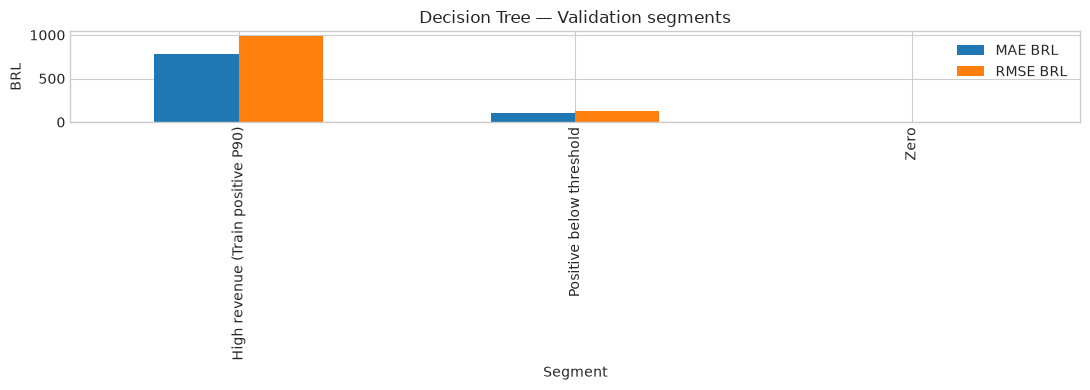

Với **Decision Tree**, MAE ở tuần 0 là **0.2834 BRL**; RMSE ở nhóm doanh thu lớn là **992.0283 BRL**, bias **-782.9470 BRL**. Bias âm ở nhóm lớn cho thấy underprediction; không thể dùng lỗi nhỏ ở tuần 0 để đại diện cho khả năng phục vụ nhóm doanh thu lớn.

In [7]:
high_threshold = float(np.quantile(revenue(y_train)[revenue(y_train) > 0], .9))
val_segments = np.where(val_revenue == 0, "Zero", np.where(val_revenue >= high_threshold, "High revenue (Train positive P90)", "Positive below threshold"))
segment_rows = []
for name, item in trained.items():
    prediction = revenue(item["model"].predict(X_val))
    for segment in np.unique(val_segments):
        mask = val_segments == segment
        errors = prediction[mask] - val_revenue[mask]
        segment_rows.append({"Model": name, "Segment": segment, "N": int(mask.sum()), "MAE BRL": np.mean(np.abs(errors)), "RMSE BRL": np.sqrt(np.mean(errors**2)), "Bias BRL": np.mean(errors)})
segmented_validation = pd.DataFrame(segment_rows)
display(segmented_validation)
leader_name = validation_table.iloc[0].Model
leader_segments = segmented_validation.loc[segmented_validation.Model == leader_name]
display(Markdown(f"Ngưỡng doanh thu lớn lấy từ Train là **{high_threshold:.2f} BRL**. Model dẫn đầu Validation tổng thể là **{leader_name}**; cần xem đồng thời lỗi ở tuần 0 và tuần doanh thu lớn, không dùng MAE tổng thể để cam kết phục vụ nhóm bán chạy."))
fig, ax = plt.subplots(figsize=(11, 4))
leader_segments.set_index("Segment")[["MAE BRL", "RMSE BRL"]].plot.bar(ax=ax)
ax.set(title=f"{leader_name} — Validation segments", ylabel="BRL")
show_figure(fig, "weekly_03_validation_segments.png")
segment_view = leader_segments.set_index("Segment")
zero_mae = segment_view.loc["Zero", "MAE BRL"]
high_rmse = segment_view.loc["High revenue (Train positive P90)", "RMSE BRL"]
high_bias = segment_view.loc["High revenue (Train positive P90)", "Bias BRL"]
display(Markdown(f"Với **{leader_name}**, MAE ở tuần 0 là **{zero_mae:.4f} BRL**; RMSE ở nhóm doanh thu lớn là **{high_rmse:.4f} BRL**, bias **{high_bias:.4f} BRL**. Bias âm ở nhóm lớn cho thấy underprediction; không thể dùng lỗi nhỏ ở tuần 0 để đại diện cho khả năng phục vụ nhóm doanh thu lớn."))


## Bàn giao

`weekly_candidates.pkl` lưu candidates đã fit, pipeline, fast-mode flag và fingerprint cache. Notebook 04 kiểm tra fingerprint trước khi sử dụng. Không thay đổi feature hoặc tham số theo kết quả Test sau đó.